In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!nvidia-smi

Fri Nov  6 06:19:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   67C    P0             29W /   70W |     639MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2
import os

In [ ]:
img=image.load_img('/content/drive/MyDrive/FACIAL DETECTION/training/happy/1HEoLBLidT2u4mhJ0oiDgig.png')

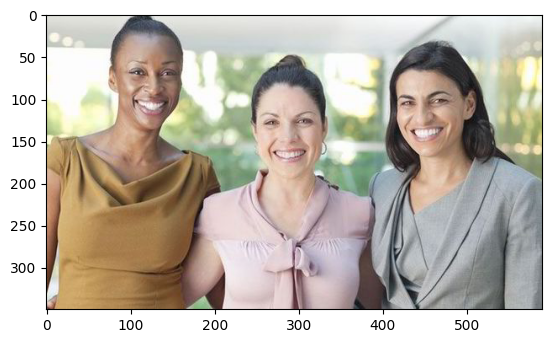

In [ ]:
plt.imshow(img)

In [ ]:
i1=cv2.imread('/content/drive/MyDrive/FACIAL DETECTION/training/happy/1HEoLBLidT2u4mhJ0oiDgig.png')
i1

array([[[241, 249, 255],
        [241, 249, 255],
        [241, 249, 255],
        ...,
        [236, 244, 254],
        [236, 244, 254],
        [236, 244, 254]],

       [[241, 249, 255],
        [241, 249, 255],
        [240, 248, 255],
        ...,
        [235, 243, 253],
        [236, 244, 254],
        [236, 244, 254]],

       [[241, 249, 255],
        [241, 249, 255],
        [240, 248, 255],
        ...,
        [235, 243, 253],
        [236, 244, 254],
        [236, 244, 254]],

       ...,

       [[ 53,  87, 100],
        [ 60,  94, 106],
        [ 65, 100, 111],
        ...,
        [ 54,  89,  86],
        [ 57,  94,  91],
        [ 57,  93,  92]],

       [[ 70, 105, 117],
        [ 63,  97, 108],
        [ 63,  98, 108],
        ...,
        [ 56,  91,  90],
        [ 54,  90,  88],
        [ 52,  87,  89]],

       [[ 56,  90, 104],
        [ 66, 100, 114],
        [ 62,  96, 108],
        ...,
        [ 55,  89,  91],
        [ 54,  89,  90],
        [ 57,  92,  97]]

In [ ]:
i1.shape

(933, 1400, 3)

In [ ]:
train=ImageDataGenerator(rescale=1/200)
validation=ImageDataGenerator(rescale=1/200)

In [ ]:
train_dataset=train.flow_from_directory('/content/drive/MyDrive/FACIAL DETECTION/training',
                                       target_size=(200,200),
                                       batch_size=32,
                                       class_mode='binary')
validation_dataset=validation.flow_from_directory('/content/drive/MyDrive/FACIAL DETECTION/validation',
                                       target_size=(200,200),
                                       batch_size=32,
                                       class_mode='binary')

Found 6 images belonging to 2 classes.
Found 0 images belonging to 3 classes.


In [ ]:
train_dataset.class_indices

{'happy': 0, 'not happy': 1}

In [ ]:
train_dataset.classes

array([0, 0, 0, 1, 1, 1], dtype=int32)

In [ ]:
# now we are applying maxpooling

model = tf.keras.models.Sequential([ tf.keras.layers.Conv2D(16,(3,3),activation = 'relu',
                                                            input_shape = (200,200,3)),
                                    tf.keras.layers.MaxPool2D(2,2), #3 filtr we applied hear
                                    #
                                    tf.keras.layers.Conv2D(32,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPool2D(2,2),
                                    #
                                    tf.keras.layers.Conv2D(64,(3,3),activation = 'relu'),
                                    tf.keras.layers.MaxPool2D(2,2),
                                    ##
                                    tf.keras.layers.Flatten(),
                                    ##
                                    tf.keras.layers.Dense(512, activation = 'relu'),
                                    #
                                    tf.keras.layers.Dense(1,activation= 'sigmoid')
                                    ]
                                    )

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(loss='binary_crossentropy',optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),metrics=['accuracy'])

In [ ]:
model_fit=model.fit(train_dataset,epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.5000 - loss: 0.6957
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.5000 - loss: 3.9374
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.5000 - loss: 5.3625
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.6667 - loss: 0.6460
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8333 - loss: 0.4938
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.8333 - loss: 0.3131
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.5000 - loss: 1.3329
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.6667 - loss: 0.4808
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 1.0000 - loss: 0.2464
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 1.0000 - loss: 0.1235
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 1.0000 - loss: 0.0617
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 1.

In [ ]:
dir_path='/content/drive/MyDrive/FACIAL DETECTION/testing'
for i in os.listdir(dir_path):
  print(i)

happy
not happy


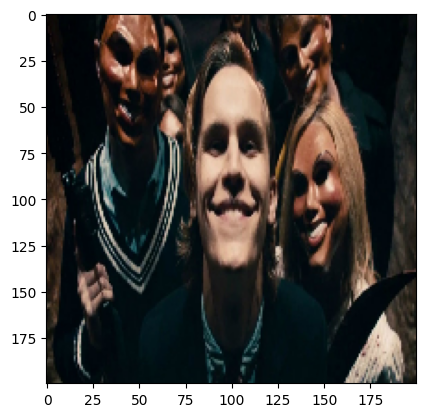

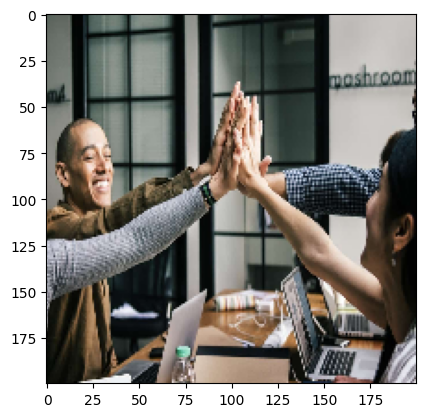

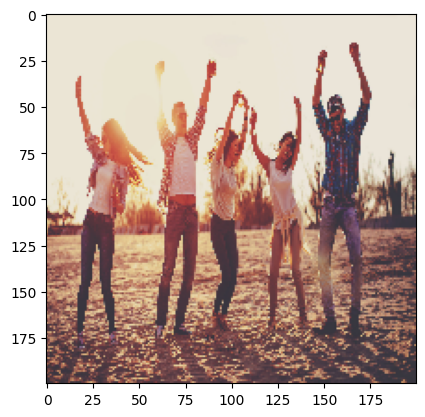

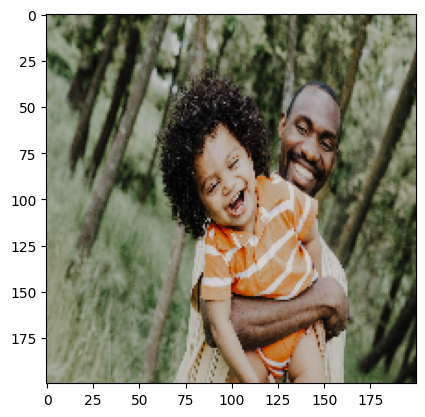

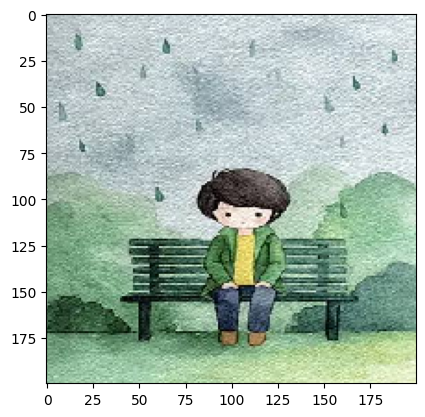

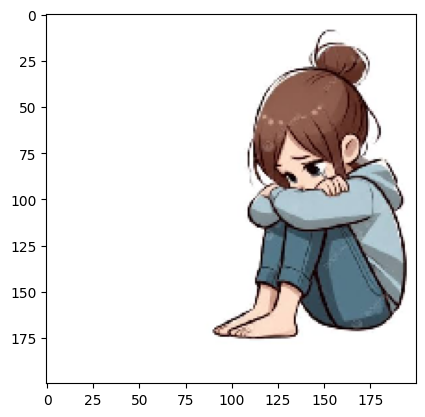

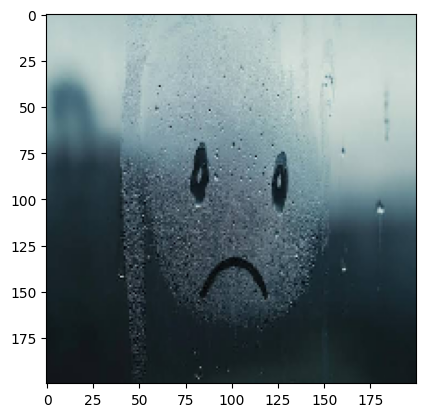

In [ ]:
dir_path='/content/drive/MyDrive/FACIAL DETECTION/testing'

for i in os.listdir(dir_path):
    for j in os.listdir(dir_path+'/'+i):
        img=image.load_img(dir_path+'/'+i+'/'+j, target_size=(200,200))
        plt.imshow(img)
        plt.show()

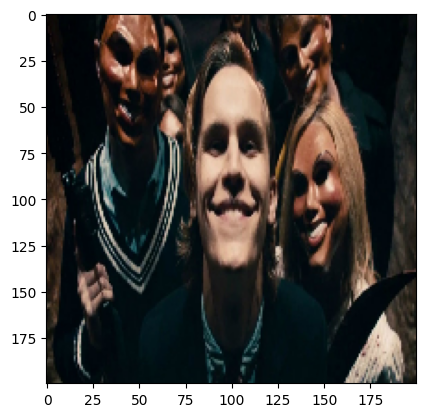

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
i am sad


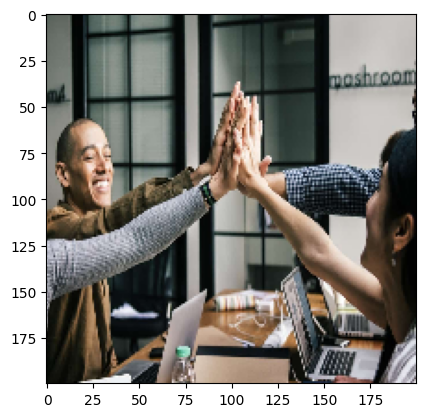

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
i am sad


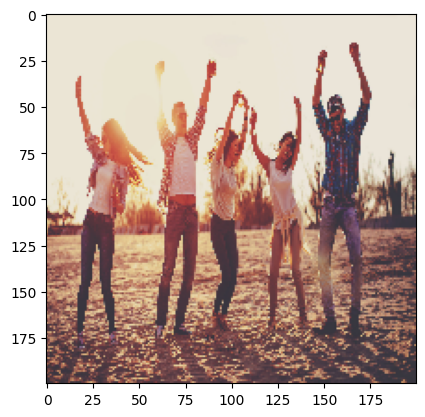

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
i am happy


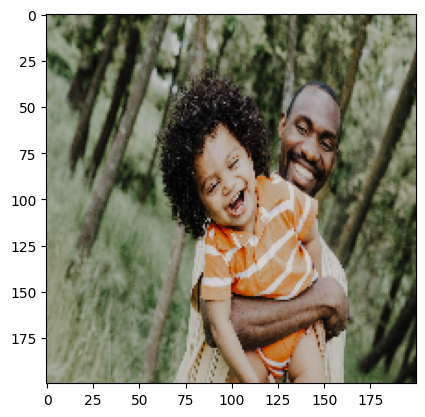

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
i am happy


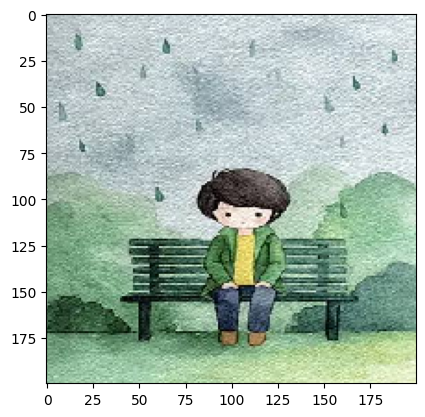

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
i am happy


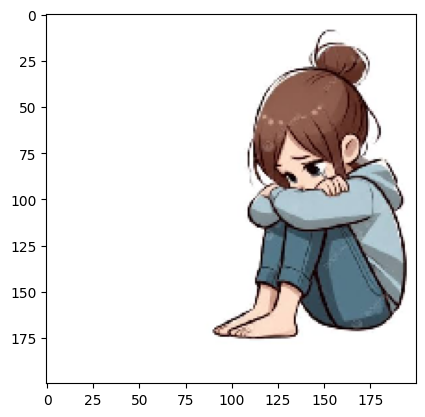

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
i am sad


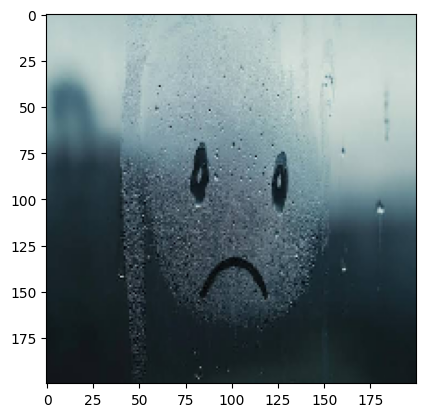

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
i am happy


In [ ]:
dir_path='/content/drive/MyDrive/FACIAL DETECTION/testing'

for i in os.listdir(dir_path):
    for j in os.listdir(dir_path+'/'+i):
        img=image.load_img(dir_path+'/'+i+'/'+j, target_size=(200,200))
        plt.imshow(img)
        plt.show()

        x=image.img_to_array(img)
        x=np.expand_dims(x,axis=0)
        images=np.vstack([x])

        val=model.predict(images)

        if val[0][0] < 0.5:
            print('i am happy')
        else:
            print('i am sad')

In [ ]:
pip install gradio

In [ ]:
import gradio as gr
from PIL import Image
import numpy as np

def predict_mood(image):
    # Resize the image to (200, 200) as expected by the model
    img = image.resize((200, 200))
    # Convert the image to a numpy array
    x = np.array(img)
    # Expand dimensions to create a batch of 1 image
    x = np.expand_dims(x, axis=0)
    # Normalize the image (if the model was trained with normalized inputs)
    # The model was trained with rescale=1/200, so we should apply the same scaling here.
    x = x / 200.0
    # Make prediction
    val = model.predict(x)[0][0]
    # Interpret the prediction
    if val < 0.5:
        return 'Happy'
    else:
        return 'Not Happy'

In [ ]:
iface = gr.Interface(
    fn=predict_mood,
    inputs=gr.Image(type="pil", label="Upload an image"),
    outputs=gr.Text(label="Predicted Mood"),
    title="Mood Classification(Happy/Not Happy)",
    description="Upload an image to classify if the person is happy or not happy.",
)
iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4862ac554f3f5aeae3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
